# Actividad 04. Proyecto en R.
## Datos del alumno :
- Nombre : David León Salas
- Numero de control : 202680124
- Correo : 202680124@ucc.mx
- Fecha : 21 Octubre 2026

Versión en R de la Actividad 02 (Python con Pandas). Se usa únicamente **R base**:
`data.frame` en lugar de Pandas, vectores en lugar de NumPy y el paquete `graphics` en lugar de matplotlib / seaborn.

Datasets utilizados:
- Spotify (spotify_data clean.csv)
- Airbnb Nueva York (Airbnb_Open_Data.csv)
- Casas en Melbourne (melb_data.csv)

# 1. Carga de datos

In [1]:
options(width = 110)

# Los csv estan en la carpeta Actividad01 del proyecto de Pandas, si no existe (Colab) se leen de GitHub
ruta_local <- "../../../Introduccion_NumpyPandas/src/Actividad01/"

if (dir.exists(ruta_local)) {
  ruta <- ruta_local
  spotify_csv <- "spotify_data clean.csv"
} else {
  ruta <- "https://raw.githubusercontent.com/DvLeu/Introduccion_NumpyPandas/main/src/Actividad01/"
  spotify_csv <- "spotify_data%20clean.csv"
}

# Valores que se leen como NA (igual que en Pandas)
valores_na <- c("", "NA", "NaN", "N/A", "null", "nan", "None")

In [2]:
# El csv de Spotify tiene comillas dentro de textos que no están escapadas, por ejemplo:
#   "Violator | The 12" Singles"
# read.csv no puede leerlo así, entonces se duplican las comillas internas ("") antes de leerlo.
lineas_spotify <- readLines(paste0(ruta, spotify_csv), encoding = "UTF-8")
impares <- lengths(regmatches(lineas_spotify, gregexpr("\"", lineas_spotify))) %% 2 == 1
cat("Líneas con comillas sin cerrar:", sum(impares), "\n")

lineas_spotify <- gsub("(?<=[^,])\"(?=[^,])", "\"\"", lineas_spotify, perl = TRUE)

df_spotify <- read.csv(text = lineas_spotify, check.names = FALSE, na.strings = valores_na, encoding = "UTF-8")
df_airbnb <- read.csv(paste0(ruta, "Airbnb_Open_Data.csv"), check.names = FALSE, na.strings = valores_na, encoding = "UTF-8")
df_melb <- read.csv(paste0(ruta, "melb_data.csv"), check.names = FALSE, na.strings = valores_na, encoding = "UTF-8")

Líneas con comillas sin cerrar: 5 


In [3]:
print(dim(df_spotify))
print(dim(df_airbnb))
print(dim(df_melb))

[1] 8582   15
[1] 102599     26
[1] 13580    21


# 2. Detección de problemas

## Spotify

In [4]:
head(df_spotify)

                track_id                                      track_name track_number track_popularity
1 3EJS5LyekDim1Tf5rBFmZl                   Trippy Mane (ft. Project Pat)            4                0
2 1oQW6G2ZiwMuHqlPpP27DB                                            OMG!            1                0
3 7mdkjzoIYlf1rx9EtBpGmU                                     Hard 2 Find            1                4
4 67rW0Zl7oB3qEpD5YWWE5w Still Get Like That (ft. Project Pat & Starrah)            8               30
5 15xptTfRBrjsppW0INUZjf                           ride me like a harley            2                0
6 4ccpCcZYseq8VrPMK1EDs0                                           BLEED            1                2
  explicit artist_name artist_popularity artist_followers                     artist_genres
1     TRUE       Diplo                77          2812821                        moombahton
2     TRUE    Yelawolf                64          2363438 country hip hop, southern hip hop
3  

In [5]:
str(df_spotify)

'data.frame':	8582 obs. of  15 variables:
 $ track_id          : chr  "3EJS5LyekDim1Tf5rBFmZl" "1oQW6G2ZiwMuHqlPpP27DB" "7mdkjzoIYlf1rx9EtBpGmU" "67rW0Zl7oB3qEpD5YWWE5w" ...
 $ track_name        : chr  "Trippy Mane (ft. Project Pat)" "OMG!" "Hard 2 Find" "Still Get Like That (ft. Project Pat & Starrah)" ...
 $ track_number      : int  4 1 1 8 2 1 1 1 1 1 ...
 $ track_popularity  : int  0 0 4 30 0 2 20 27 16 33 ...
 $ explicit          : logi  TRUE TRUE TRUE TRUE TRUE FALSE ...
 $ artist_name       : chr  "Diplo" "Yelawolf" "Riff Raff" "Diplo" ...
 $ artist_popularity : int  77 64 48 77 48 46 30 49 6 48 ...
 $ artist_followers  : int  2812821 2363438 193302 2813710 8682 7218 1657 8802 475 154802 ...
 $ artist_genres     : chr  "moombahton" "country hip hop, southern hip hop" NA "moombahton" ...
 $ album_id          : chr  "5QRFnGnBeMGePBKF2xTz5z" "4SUmmwnv0xTjRcLdjczGg2" "3E3zEAL8gUYWaLYB9L7gbp" "5QRFnGnBeMGePBKF2xTz5z" ...
 $ album_name        : chr  "d00mscrvll, Vol. 1" "OMG!" "Hard 2

In [6]:
# Nulos

colSums(is.na(df_spotify))

          track_id         track_name       track_number   track_popularity           explicit 
                 0                  0                  0                  0                  0 
       artist_name  artist_popularity   artist_followers      artist_genres           album_id 
                 3                  0                  0               3361                  0 
        album_name album_release_date album_total_tracks         album_type track_duration_min 
                 0                  0                  0                  0                  0 


In [7]:
# Duplicados

sum(duplicated(df_spotify))

[1] 0


In [8]:
summary(df_spotify[sapply(df_spotify, is.numeric)])

  track_number     track_popularity artist_popularity artist_followers    album_total_tracks
 Min.   :  1.000   Min.   : 0.00    Min.   :  0.00    Min.   :        0   Min.   :  1.00    
 1st Qu.:  1.000   1st Qu.:39.00    1st Qu.: 60.00    1st Qu.:   462320   1st Qu.:  6.00    
 Median :  4.000   Median :58.00    Median : 74.00    Median :  6105547   Median : 13.00    
 Mean   :  5.773   Mean   :52.36    Mean   : 69.73    Mean   : 24034719   Mean   : 13.79    
 3rd Qu.:  9.000   3rd Qu.:71.00    3rd Qu.: 84.00    3rd Qu.: 27252551   3rd Qu.: 17.00    
 Max.   :102.000   Max.   :99.00    Max.   :100.00    Max.   :145542136   Max.   :181.00    
 track_duration_min
 Min.   : 0.070    
 1st Qu.: 2.880    
 Median : 3.445    
 Mean   : 3.493    
 3rd Qu.: 3.990    
 Max.   :13.510    


In [9]:
# La popularidad debe estar entre 0 y 100 y la duracion debe ser mayor a 0

print(nrow(df_spotify[df_spotify$track_popularity < 0 | df_spotify$track_popularity > 100, ]))
print(nrow(df_spotify[df_spotify$track_duration_min <= 0, ]))

[1] 0
[1] 0


En Spotify no hay duplicados ni valores fuera de rango, pero faltan muchos géneros (artist_genres) y algunos nombres de artista. La fecha album_release_date viene como texto. Además, el archivo tiene 5 líneas con comillas mal escapadas que se corrigieron al leerlo.

## Airbnb

In [10]:
head(df_airbnb)

       id                                             NAME     host id host_identity_verified host name
1 1001254               Clean & quiet apt home by the park 80014485718            unconfirmed  Madaline
2 1002102                            Skylit Midtown Castle 52335172823               verified     Jenna
3 1002403              THE VILLAGE OF HARLEM....NEW YORK ! 78829239556                   <NA>     Elise
4 1002755                                             <NA> 85098326012            unconfirmed     Garry
5 1003689 Entire Apt: Spacious Studio/Loft by central park 92037596077               verified    Lyndon
6 1004098        Large Cozy 1 BR Apartment In Midtown East 45498551794               verified  Michelle
  neighbourhood group neighbourhood      lat      long       country country code instant_bookable
1            Brooklyn    Kensington 40.64749 -73.97237 United States           US            FALSE
2           Manhattan       Midtown 40.75362 -73.98377 United States      

In [11]:
str(df_airbnb)

'data.frame':	102599 obs. of  26 variables:
 $ id                            : int  1001254 1002102 1002403 1002755 1003689 1004098 1004650 1005202 1005754 1006307 ...
 $ NAME                          : chr  "Clean & quiet apt home by the park" "Skylit Midtown Castle" "THE VILLAGE OF HARLEM....NEW YORK !" NA ...
 $ host id                       : num  8.00e+10 5.23e+10 7.88e+10 8.51e+10 9.20e+10 ...
 $ host_identity_verified        : chr  "unconfirmed" "verified" NA "unconfirmed" ...
 $ host name                     : chr  "Madaline" "Jenna" "Elise" "Garry" ...
 $ neighbourhood group           : chr  "Brooklyn" "Manhattan" "Manhattan" "Brooklyn" ...
 $ neighbourhood                 : chr  "Kensington" "Midtown" "Harlem" "Clinton Hill" ...
 $ lat                           : num  40.6 40.8 40.8 40.7 40.8 ...
 $ long                          : num  -74 -74 -73.9 -74 -73.9 ...
 $ country                       : chr  "United States" "United States" "United States" "United States" ...
 $ cou

In [12]:
colSums(is.na(df_airbnb))

                            id                           NAME                        host id 
                             0                            250                              0 
        host_identity_verified                      host name            neighbourhood group 
                           289                            406                             29 
                 neighbourhood                            lat                           long 
                            16                              8                              8 
                       country                   country code               instant_bookable 
                           532                            131                            105 
           cancellation_policy                      room type              Construction year 
                            76                              0                            214 
                         price                    service fe

In [13]:
sum(duplicated(df_airbnb))

[1] 541


In [14]:
summary(df_airbnb[sapply(df_airbnb, is.numeric)])

       id              host id               lat             long        Construction year
 Min.   : 1001254   Min.   :1.236e+08   Min.   :40.50   Min.   :-74.25   Min.   :2003     
 1st Qu.:15085814   1st Qu.:2.458e+10   1st Qu.:40.69   1st Qu.:-73.98   1st Qu.:2007     
 Median :29136603   Median :4.912e+10   Median :40.72   Median :-73.95   Median :2012     
 Mean   :29146235   Mean   :4.925e+10   Mean   :40.73   Mean   :-73.95   Mean   :2012     
 3rd Qu.:43201198   3rd Qu.:7.400e+10   3rd Qu.:40.76   3rd Qu.:-73.93   3rd Qu.:2017     
 Max.   :57367417   Max.   :9.876e+10   Max.   :40.92   Max.   :-73.71   Max.   :2022     
                                        NA's   :8       NA's   :8        NA's   :214      
 minimum nights      number of reviews reviews per month review rate number calculated host listings count
 Min.   :-1223.000   Min.   :   0.00   Min.   : 0.010    Min.   :1.000      Min.   :  1.000               
 1st Qu.:    2.000   1st Qu.:   1.00   1st Qu.: 0.220    1

In [15]:
# price y service fee vienen con $

head(df_airbnb[c("price", "service fee")])

  price service fee
1 $966        $193 
2 $142         $28 
3 $620        $124 
4 $368         $74 
5 $204         $41 
6 $577        $115 


In [16]:
sort(table(df_airbnb[["neighbourhood group"]]), decreasing = TRUE)


    Manhattan      Brooklyn        Queens         Bronx Staten Island       brookln      manhatan 
        43792         41842         13267          2712           955             1             1 


In [17]:
# Disponibilidad fuera de 0 a 365

sum(df_airbnb[["availability 365"]] < 0 | df_airbnb[["availability 365"]] > 365, na.rm = TRUE)

[1] 3214


In [18]:
# Noches minimas negativas o en 0

sum(df_airbnb[["minimum nights"]] <= 0, na.rm = TRUE)

[1] 13


In [19]:
print(unique(df_airbnb$country))
print(unique(df_airbnb[["country code"]]))

[1] "United States" NA             
[1] "US" NA  


En Airbnb hay 541 filas duplicadas, price y service fee son texto, hay dos zonas mal escritas ("brookln" y "manhatan"), disponibilidades fuera de rango y noches mínimas negativas. country y country code solo tienen un valor y license está casi vacía.

## Melbourne

In [20]:
head(df_melb)

      Suburb          Address Rooms Type   Price Method SellerG      Date Distance Postcode Bedroom2 Bathroom
1 Abbotsford     85 Turner St     2    h 1480000      S  Biggin 3/12/2016      2.5     3067        2        1
2 Abbotsford  25 Bloomburg St     2    h 1035000      S  Biggin 4/02/2016      2.5     3067        2        1
3 Abbotsford     5 Charles St     3    h 1465000     SP  Biggin 4/03/2017      2.5     3067        3        2
4 Abbotsford 40 Federation La     3    h  850000     PI  Biggin 4/03/2017      2.5     3067        3        2
5 Abbotsford      55a Park St     4    h 1600000     VB  Nelson 4/06/2016      2.5     3067        3        1
6 Abbotsford   129 Charles St     2    h  941000      S  Jellis 7/05/2016      2.5     3067        2        1
  Car Landsize BuildingArea YearBuilt CouncilArea Lattitude Longtitude            Regionname Propertycount
1   1      202           NA        NA       Yarra  -37.7996   144.9984 Northern Metropolitan          4019
2   0      156  

In [21]:
str(df_melb)

'data.frame':	13580 obs. of  21 variables:
 $ Suburb       : chr  "Abbotsford" "Abbotsford" "Abbotsford" "Abbotsford" ...
 $ Address      : chr  "85 Turner St" "25 Bloomburg St" "5 Charles St" "40 Federation La" ...
 $ Rooms        : int  2 2 3 3 4 2 3 2 1 2 ...
 $ Type         : chr  "h" "h" "h" "h" ...
 $ Price        : num  1480000 1035000 1465000 850000 1600000 ...
 $ Method       : chr  "S" "S" "SP" "PI" ...
 $ SellerG      : chr  "Biggin" "Biggin" "Biggin" "Biggin" ...
 $ Date         : chr  "3/12/2016" "4/02/2016" "4/03/2017" "4/03/2017" ...
 $ Distance     : num  2.5 2.5 2.5 2.5 2.5 2.5 2.5 2.5 2.5 2.5 ...
 $ Postcode     : num  3067 3067 3067 3067 3067 ...
 $ Bedroom2     : num  2 2 3 3 3 2 4 2 1 3 ...
 $ Bathroom     : num  1 1 2 2 1 1 2 1 1 1 ...
 $ Car          : num  1 0 0 1 2 0 0 2 1 2 ...
 $ Landsize     : num  202 156 134 94 120 181 245 256 0 220 ...
 $ BuildingArea : num  NA 79 150 NA 142 NA 210 107 NA 75 ...
 $ YearBuilt    : num  NA 1900 1900 NA 2014 ...
 $ CouncilAr

In [22]:
colSums(is.na(df_melb))

       Suburb       Address         Rooms          Type         Price        Method       SellerG 
            0             0             0             0             0             0             0 
         Date      Distance      Postcode      Bedroom2      Bathroom           Car      Landsize 
            0             0             0             0             0            62             0 
 BuildingArea     YearBuilt   CouncilArea     Lattitude    Longtitude    Regionname Propertycount 
         6450          5375          1369             0             0             0             0 


In [23]:
sum(duplicated(df_melb))

[1] 0


In [24]:
summary(df_melb[sapply(df_melb, is.numeric)])

     Rooms            Price            Distance        Postcode       Bedroom2         Bathroom    
 Min.   : 1.000   Min.   :  85000   Min.   : 0.00   Min.   :3000   Min.   : 0.000   Min.   :0.000  
 1st Qu.: 2.000   1st Qu.: 650000   1st Qu.: 6.10   1st Qu.:3044   1st Qu.: 2.000   1st Qu.:1.000  
 Median : 3.000   Median : 903000   Median : 9.20   Median :3084   Median : 3.000   Median :1.000  
 Mean   : 2.938   Mean   :1075684   Mean   :10.14   Mean   :3105   Mean   : 2.915   Mean   :1.534  
 3rd Qu.: 3.000   3rd Qu.:1330000   3rd Qu.:13.00   3rd Qu.:3148   3rd Qu.: 3.000   3rd Qu.:2.000  
 Max.   :10.000   Max.   :9000000   Max.   :48.10   Max.   :3977   Max.   :20.000   Max.   :8.000  
                                                                                                   
      Car           Landsize         BuildingArea     YearBuilt      Lattitude        Longtitude   
 Min.   : 0.00   Min.   :     0.0   Min.   :    0   Min.   :1196   Min.   :-38.18   Min.   :144.4  


In [25]:
# Casas con superficie construida en 0

sum(df_melb$BuildingArea == 0, na.rm = TRUE)

[1] 17


In [26]:
# Años de construccion muy viejos o despues de la venta

anio_venta <- as.integer(format(as.Date(df_melb$Date, format = "%d/%m/%Y"), "%Y"))
incorrectos <- which(df_melb$YearBuilt < 1800 | df_melb$YearBuilt > anio_venta)
df_melb[incorrectos, c("Date", "YearBuilt")]

           Date YearBuilt
442   3/12/2016      2017
1235 24/09/2016      2018
3490 23/04/2016      2017
4283 28/05/2016      2017
5154 17/09/2016      2017
7061 30/07/2016      2017
9969 24/06/2017      1196


En Melbourne no hay duplicados. BuildingArea y YearBuilt tienen muchos nulos, superficies en 0 y algunos años imposibles. Car y CouncilArea tienen pocos nulos y Landsize tiene valores muy grandes.

# 3. Limpieza

Estrategia:
- Eliminar duplicados
- Cambiar tipos de datos (fechas y precios)
- Los valores incorrectos se cambian a NA
- Rellenar nulos con la mediana o con "Sin dato"
- Inferir valores cuando la columna solo tiene un valor
- Eliminar columnas casi vacías
- Recortar valores extremos

## Spotify

In [27]:
spotify <- df_spotify
spotify <- spotify[!duplicated(spotify), ]

In [28]:
spotify$album_release_date <- as.Date(spotify$album_release_date)
class(spotify$album_release_date)

[1] "Date"


In [29]:
spotify$artist_name[is.na(spotify$artist_name)] <- "Sin dato"
spotify$artist_genres[is.na(spotify$artist_genres)] <- "Sin dato"
colSums(is.na(spotify))

          track_id         track_name       track_number   track_popularity           explicit 
                 0                  0                  0                  0                  0 
       artist_name  artist_popularity   artist_followers      artist_genres           album_id 
                 0                  0                  0                  0                  0 
        album_name album_release_date album_total_tracks         album_type track_duration_min 
                 0                  0                  0                  0                  0 


## Airbnb

In [30]:
airbnb <- df_airbnb

# nombres de columnas en minusculas y sin espacios
names(airbnb) <- gsub(" ", "_", tolower(names(airbnb)))
airbnb <- airbnb[!duplicated(airbnb), ]
dim(airbnb)

[1] 102058     26


In [31]:
airbnb$neighbourhood_group[airbnb$neighbourhood_group %in% "brookln"] <- "Brooklyn"
airbnb$neighbourhood_group[airbnb$neighbourhood_group %in% "manhatan"] <- "Manhattan"
sort(table(airbnb$neighbourhood_group), decreasing = TRUE)


    Manhattan      Brooklyn        Queens         Bronx Staten Island 
        43558         41631         13197          2694           949 


In [32]:
# Quitar $ y , para pasar a numero
# suppressWarnings --> lo que no se pueda convertir queda como NA (igual que errors="coerce")

a_numero <- function(texto) {
  suppressWarnings(as.numeric(gsub("[$,]", "", texto)))
}

airbnb$price <- a_numero(airbnb$price)
airbnb$service_fee <- a_numero(airbnb$service_fee)
summary(airbnb[c("price", "service_fee")])

     price         service_fee 
 Min.   :  50.0   Min.   : 10  
 1st Qu.: 340.0   1st Qu.: 68  
 Median : 625.0   Median :125  
 Mean   : 625.4   Mean   :125  
 3rd Qu.: 913.0   3rd Qu.:183  
 Max.   :1200.0   Max.   :240  
 NA's   :247      NA's   :273  


In [33]:
# valores fuera de rango a NA

airbnb$availability_365[which(airbnb$availability_365 < 0 | airbnb$availability_365 > 365)] <- NA
airbnb$minimum_nights[which(airbnb$minimum_nights <= 0)] <- NA

In [34]:
airbnb$last_review <- as.Date(airbnb$last_review, format = "%m/%d/%Y")

In [35]:
# Si no tiene reseñas entonces reviews_per_month es 0

sin_resenas <- which(airbnb$number_of_reviews == 0 & is.na(airbnb$reviews_per_month))
airbnb$reviews_per_month[sin_resenas] <- 0

In [36]:
# country y country_code solo tienen un valor, se rellenan con ese

airbnb$country[is.na(airbnb$country)] <- "United States"
airbnb$country_code[is.na(airbnb$country_code)] <- "US"

In [37]:
texto <- c("name", "host_name", "neighbourhood_group", "neighbourhood", "host_identity_verified", "cancellation_policy", "house_rules")
for (columna in texto) {
  airbnb[[columna]][is.na(airbnb[[columna]])] <- "Sin dato"
}

In [38]:
# license casi no tiene datos

sum(is.na(airbnb$license))

[1] 102056


In [39]:
airbnb$license <- NULL
colSums(is.na(airbnb))

                            id                           name                        host_id 
                             0                              0                              0 
        host_identity_verified                      host_name            neighbourhood_group 
                             0                              0                              0 
                 neighbourhood                            lat                           long 
                             0                              8                              8 
                       country                   country_code               instant_bookable 
                             0                              0                            105 
           cancellation_policy                      room_type              construction_year 
                             0                              0                            214 
                         price                    service_fe

## Melbourne

In [40]:
melb <- df_melb
names(melb) <- tolower(names(melb))
melb$date <- as.Date(melb$date, format = "%d/%m/%Y")

In [41]:
anio <- as.integer(format(melb$date, "%Y"))
melb$buildingarea[which(melb$buildingarea == 0)] <- NA
melb$yearbuilt[which(melb$yearbuilt < 1800 | melb$yearbuilt > anio)] <- NA

In [42]:
# car se rellena con la mediana segun el tipo de casa

tapply(melb$car, melb$type, median, na.rm = TRUE)

h t u 
2 2 1 


In [43]:
mediana_tipo <- ave(melb$car, melb$type, FUN = function(x) median(x, na.rm = TRUE))
melb$car[is.na(melb$car)] <- mediana_tipo[is.na(melb$car)]
melb$councilarea[is.na(melb$councilarea)] <- "Sin dato"

In [44]:
# Recorte de landsize en el percentil 99

p99 <- quantile(melb$landsize, 0.99)
melb$landsize_recortado <- pmin(melb$landsize, p99)
summary(melb[c("landsize", "landsize_recortado")])

    landsize        landsize_recortado
 Min.   :     0.0   Min.   :   0.0    
 1st Qu.:   177.0   1st Qu.: 177.0    
 Median :   440.0   Median : 440.0    
 Mean   :   558.4   Mean   : 466.8    
 3rd Qu.:   651.0   3rd Qu.: 651.0    
 Max.   :433014.0   Max.   :2959.8    


In [45]:
colSums(is.na(melb))

            suburb            address              rooms               type              price 
                 0                  0                  0                  0                  0 
            method            sellerg               date           distance           postcode 
                 0                  0                  0                  0                  0 
          bedroom2           bathroom                car           landsize       buildingarea 
                 0                  0                  0                  0               6467 
         yearbuilt        councilarea          lattitude         longtitude         regionname 
              5382                  0                  0                  0                  0 
     propertycount landsize_recortado 
                 0                  0 


Los nulos de buildingarea y yearbuilt se quedan porque son casi la mitad de los registros.

# 4. Nuevas columnas y memoria

In [46]:
# Spotify

spotify$anio <- as.integer(format(spotify$album_release_date, "%Y"))
spotify$duracion_seg <- spotify$track_duration_min * 60
spotify$popularidad <- cut(spotify$track_popularity, breaks = c(-1, 33, 66, 100), labels = c("Baja", "Media", "Alta"))
sort(table(spotify$popularidad), decreasing = TRUE)


Media  Alta  Baja 
 3956  2912  1714 


In [47]:
aggregate(cbind(track_popularity, track_duration_min) ~ album_type, data = spotify, FUN = mean)

   album_type track_popularity track_duration_min
1       album         55.65505           3.625668
2 compilation         40.51282           3.572249
3      single         46.35647           3.124024


In [48]:
# Airbnb

airbnb$precio_total <- airbnb$price + airbnb$service_fee
airbnb$disponibilidad <- airbnb$availability_365 / 365
head(airbnb[c("price", "service_fee", "precio_total", "disponibilidad")])

  price service_fee precio_total disponibilidad
1   966         193         1159      0.7835616
2   142          28          170      0.6246575
3   620         124          744      0.9643836
4   368          74          442      0.8821918
5   204          41          245      0.7917808
6   577         115          692             NA


In [49]:
tapply(airbnb$price, airbnb$neighbourhood_group, median, na.rm = TRUE)

        Bronx      Brooklyn     Manhattan        Queens      Sin dato Staten Island 
          632           626           621           628           661           628 


In [50]:
# Melbourne

melb$antiguedad <- as.integer(format(melb$date, "%Y")) - melb$yearbuilt
melb$precio_m2 <- melb$price / melb$buildingarea
head(melb[c("price", "antiguedad", "precio_m2")])

    price antiguedad precio_m2
1 1480000         NA        NA
2 1035000        116 13101.266
3 1465000        117  9766.667
4  850000         NA        NA
5 1600000          2 11267.606
6  941000         NA        NA


In [51]:
# Precios atipicos con el rango intercuartilico, solo se marcan

q1 <- quantile(melb$price, 0.25)
q3 <- quantile(melb$price, 0.75)
iqr <- q3 - q1
melb$atipico <- melb$price < q1 - 1.5 * iqr | melb$price > q3 + 1.5 * iqr
sum(melb$atipico)

[1] 612


In [52]:
# na.action = na.pass para que no se eliminen las filas con buildingarea vacío
aggregate(cbind(price, buildingarea) ~ type, data = melb, FUN = median, na.rm = TRUE, na.action = na.pass)

  type   price buildingarea
1    h 1080000          144
2    t  846750          130
3    u  560000           75


In [53]:
# ifelse() --> casas a 10 km o menos del centro (equivalente a np.where)

melb$cerca_centro <- ifelse(melb$distance <= 10, "Si", "No")
tapply(melb$price, melb$cerca_centro, median)

    No     Si 
835000 980000 


**Consultas**

In [54]:
# Las 10 canciones mas populares

top <- spotify[order(spotify$track_popularity, decreasing = TRUE), c("track_name", "artist_name", "album_type", "track_popularity")]
head(top, 10)

                                           track_name   artist_name album_type track_popularity
458                                            Golden       HUNTR/X      album               99
89                                            Opalite  Taylor Swift      album               97
102                                  Elizabeth Taylor  Taylor Swift      album               95
338                                        Man I Need   Olivia Dean     single               95
104                                     Father Figure  Taylor Swift      album               94
451                                          Soda Pop     Saja Boys      album               94
1135                               BIRDS OF A FEATHER Billie Eilish      album               94
80   The Life of a Showgirl (feat. Sabrina Carpenter)  Taylor Swift      album               93
94                                  Actually Romantic  Taylor Swift      album               93
96                                      

In [55]:
# Anuncios de Manhattan con calificacion 5 y mas reseñas

manhattan <- airbnb[which(airbnb$neighbourhood_group == "Manhattan" & airbnb$review_rate_number == 5),
                    c("name", "room_type", "price", "number_of_reviews")]
head(manhattan[order(manhattan$number_of_reviews, decreasing = TRUE), ], 10)

                                                    name       room_type price number_of_reviews
53824                                         City Queen      Hotel room   451               583
49916 Private Room in Spacious Quiet Apt., Elevator Bldg    Private room   288               567
63881                  Penthouse Studio East 50s Terrace    Private room   167               490
50839    Amazing East Village XL ground floor Apartment! Entire home/apt  1178               451
2165                 TriBeCa 2500 Sq Ft w/ Priv Elevator Entire home/apt    70               447
70341                TriBeCa 2500 Sq Ft w/ Priv Elevator Entire home/apt    70               447
62950             Location is Everything. And Quiet Too!    Private room   233               446
53145                     S+ Location Midtown Studio Apt Entire home/apt  1034               418
67970                Prime location near Central Park !!    Private room  1042               403
53213       ☆ STUDIO East Vill

In [56]:
# Precio mediano por region

sort(tapply(melb$price, melb$regionname, median), decreasing = TRUE)

     Southern Metropolitan       Eastern Metropolitan South-Eastern Metropolitan      Northern Metropolitan 
                   1250000                    1010000                     850000                     806250 
      Western Metropolitan           Eastern Victoria          Northern Victoria           Western Victoria 
                    793000                     670000                     540000                     400000 


**Memoria**

Las columnas de texto con pocos valores se cambian a factor (equivalente a category). R no tiene int8 ni float32, así que los números enteros guardados como double (8 bytes) se cambian a integer (4 bytes).

In [57]:
memoria_mb <- function(df) {
  as.numeric(object.size(df)) / 1024^2
}

print(memoria_mb(spotify))
print(memoria_mb(airbnb))
print(memoria_mb(melb))

[1] 3.059814
[1] 24.92683
[1] 3.485466


In [58]:
spotify$album_type <- factor(spotify$album_type)

for (columna in c("neighbourhood_group", "room_type", "cancellation_policy", "host_identity_verified", "country", "country_code")) {
  airbnb[[columna]] <- factor(airbnb[[columna]])
}
for (columna in c("price", "service_fee", "precio_total")) {
  airbnb[[columna]] <- as.integer(airbnb[[columna]])
}

for (columna in c("type", "method", "regionname", "councilarea")) {
  melb[[columna]] <- factor(melb[[columna]])
}
for (columna in c("price", "postcode", "bedroom2", "bathroom", "car", "landsize", "propertycount")) {
  melb[[columna]] <- as.integer(melb[[columna]])
}

In [59]:
print(memoria_mb(spotify))
print(memoria_mb(airbnb))
print(memoria_mb(melb))

[1] 3.027473
[1] 21.42529
[1] 2.917488


# 5. Visualizaciones

In [60]:
options(repr.plot.width = 9, repr.plot.height = 6)   # tamaño de las gráficas en Jupyter

# Mapa de calor de una matriz de correlación con los valores escritos en cada celda
mapa_calor <- function(m, titulo) {
  n <- ncol(m)
  z <- t(m[n:1, ])
  colores <- colorRampPalette(c("#f7fbff", "#6baed6", "#08306b"))(100)
  rango <- range(m, na.rm = TRUE)
  par(mar = c(10, 10, 3, 2))
  image(1:n, 1:n, z, col = colores, zlim = rango, axes = FALSE, xlab = "", ylab = "", main = titulo)
  axis(1, at = 1:n, labels = colnames(m), las = 2)
  axis(2, at = 1:n, labels = rev(rownames(m)), las = 1)
  text(rep(1:n, n), rep(1:n, each = n), sprintf("%.2f", z),
       col = ifelse(z > mean(rango), "white", "black"))
}

# Etiqueta en negritas con fondo blanco sobre cada mediana (equivalente al bbox de matplotlib)
etiquetas_medianas <- function(medianas, textos) {
  x <- seq_along(medianas)
  ancho <- strwidth(textos, font = 2) * 1.15
  alto <- strheight(textos, font = 2) * 1.8
  y <- medianas + alto / 2
  rect(x - ancho / 2, y - alto / 2, x + ancho / 2, y + alto / 2, col = adjustcolor("white", alpha.f = 0.85), border = NA)
  text(x, y, textos, font = 2)
}

# Eje y con números completos (sin notación científica)
eje_y_completo <- function(valores) {
  marcas <- pretty(valores)
  axis(2, at = marcas, labels = format(marcas, big.mark = ",", scientific = FALSE), las = 1, cex.axis = 0.8)
}

## Spotify

In [61]:
cor_spotify <- cor(spotify[c("track_popularity", "artist_popularity", "artist_followers", "track_duration_min")], use = "pairwise.complete.obs")
cor_spotify

                   track_popularity artist_popularity artist_followers track_duration_min
track_popularity          1.0000000         0.4669028        0.2320190          0.1055599
artist_popularity         0.4669028         1.0000000        0.6355791          0.2077690
artist_followers          0.2320190         0.6355791        1.0000000          0.1721398
track_duration_min        0.1055599         0.2077690        0.1721398          1.0000000


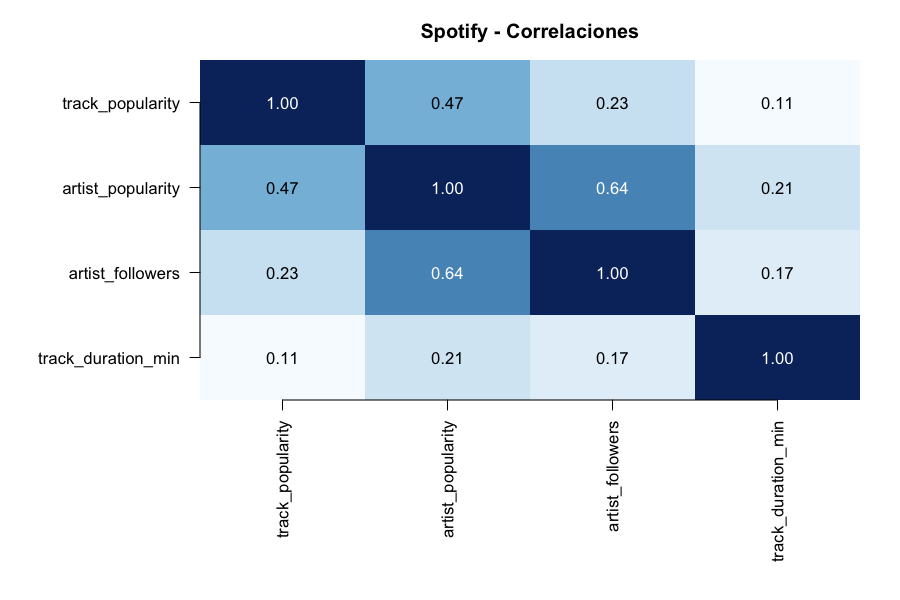

In [62]:
mapa_calor(cor_spotify, "Spotify - Correlaciones")

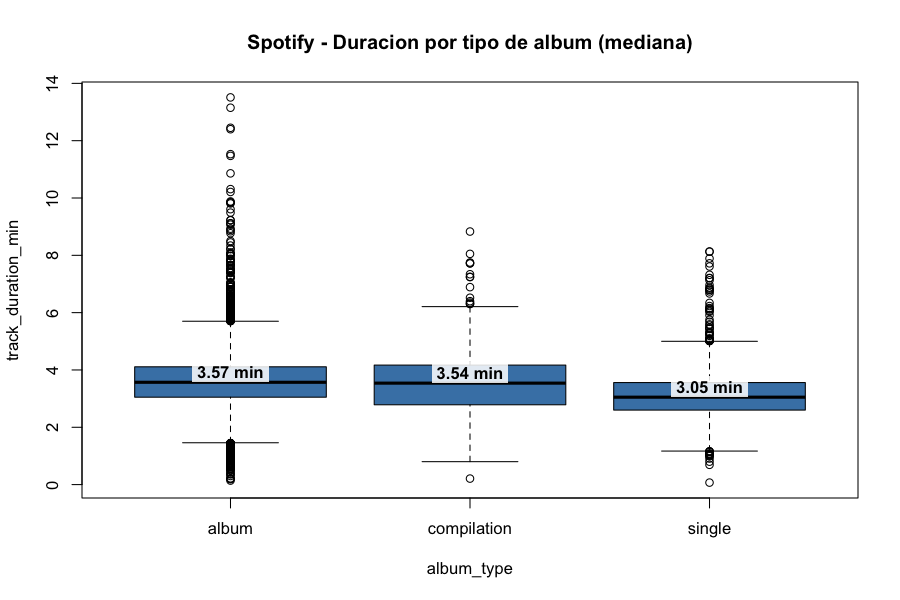

In [63]:
caja <- boxplot(track_duration_min ~ album_type, data = spotify, col = "steelblue",
                main = "Spotify - Duracion por tipo de album (mediana)", xlab = "album_type", ylab = "track_duration_min")

# mediana de cada caja
medianas <- caja$stats[3, ]
etiquetas_medianas(medianas, paste(round(medianas, 2), "min"))

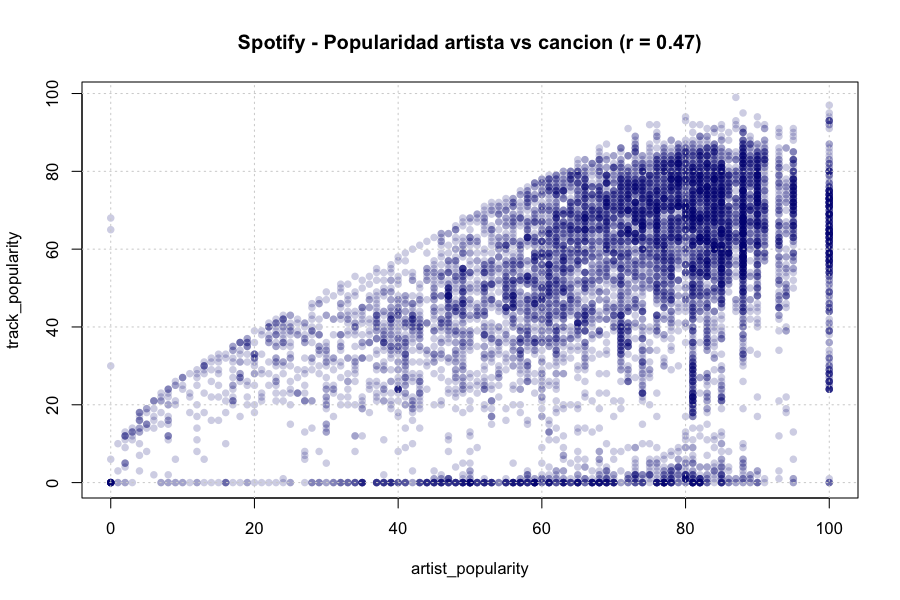

In [64]:
r <- cor(spotify$artist_popularity, spotify$track_popularity)

plot(spotify$artist_popularity, spotify$track_popularity, col = adjustcolor("navy", alpha.f = 0.2), pch = 16,
     main = paste0("Spotify - Popularidad artista vs cancion (r = ", round(r, 2), ")"),
     xlab = "artist_popularity", ylab = "track_popularity")
grid()

## Airbnb

In [65]:
cor_airbnb <- cor(airbnb[c("price", "service_fee", "minimum_nights", "number_of_reviews", "review_rate_number", "availability_365")], use = "pairwise.complete.obs")
cor_airbnb

                          price  service_fee minimum_nights number_of_reviews review_rate_number
price               1.000000000  0.999990875   -0.002716947       0.005085441       -0.004647178
service_fee         0.999990875  1.000000000   -0.002899033       0.004977842       -0.004461332
minimum_nights     -0.002716947 -0.002899033    1.000000000      -0.050536492       -0.002718221
number_of_reviews   0.005085441  0.004977842   -0.050536492       1.000000000       -0.018278737
review_rate_number -0.004647178 -0.004461332   -0.002718221      -0.018278737        1.000000000
availability_365   -0.001600949 -0.001866396    0.070361776       0.099624985        0.003370163
                   availability_365
price                  -0.001600949
service_fee            -0.001866396
minimum_nights          0.070361776
number_of_reviews       0.099624985
review_rate_number      0.003370163
availability_365        1.000000000


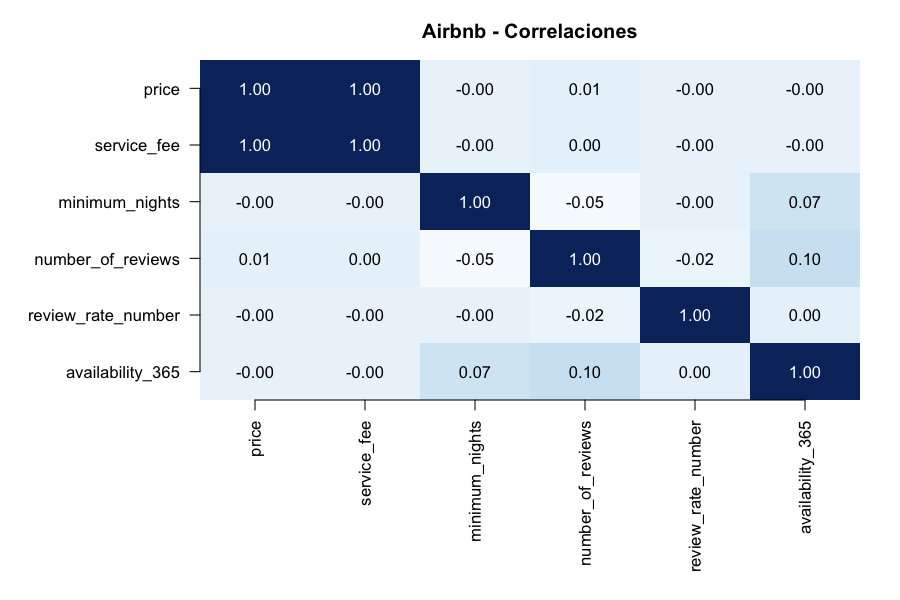

In [66]:
mapa_calor(cor_airbnb, "Airbnb - Correlaciones")

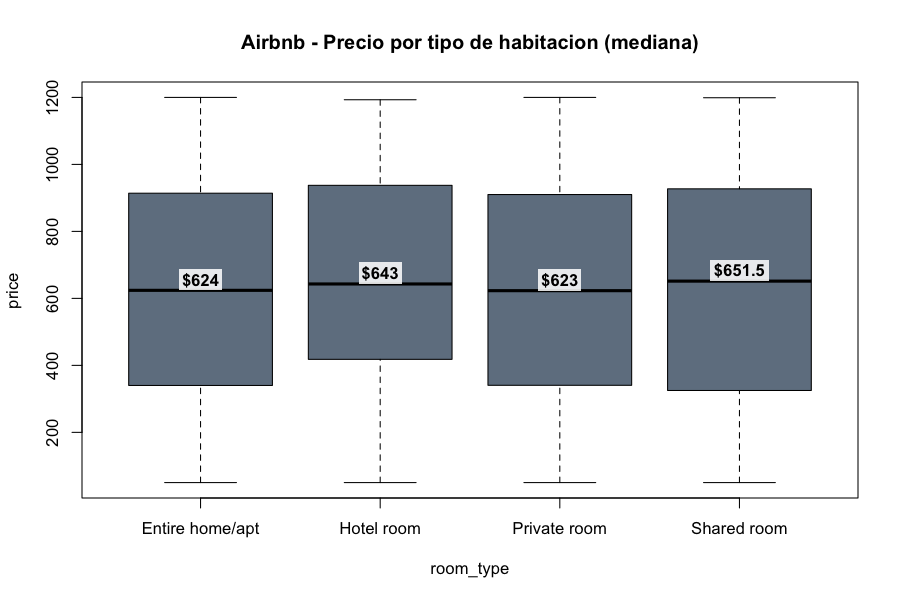

In [67]:
caja <- boxplot(price ~ room_type, data = airbnb, col = "slategray",
                main = "Airbnb - Precio por tipo de habitacion (mediana)", xlab = "room_type", ylab = "price")

medianas <- caja$stats[3, ]
etiquetas_medianas(medianas, paste0("$", medianas))

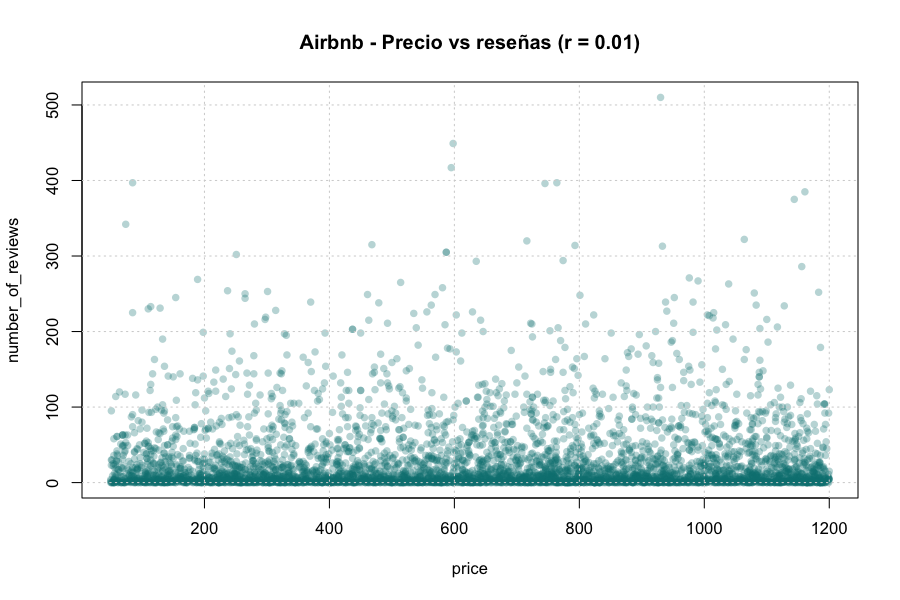

In [68]:
# muestra de 5000 porque son muchos puntos, la r se calcula con todos los datos

r <- cor(airbnb$price, airbnb$number_of_reviews, use = "complete.obs")
set.seed(1)
muestra <- airbnb[sample(nrow(airbnb), 5000), ]

plot(muestra$price, muestra$number_of_reviews, col = adjustcolor("#008080", alpha.f = 0.3), pch = 16,
     main = paste0("Airbnb - Precio vs reseñas (r = ", round(r, 2), ")"),
     xlab = "price", ylab = "number_of_reviews")
grid()

## Melbourne

In [69]:
cor_melb <- cor(melb[c("price", "rooms", "distance", "bathroom", "car", "landsize_recortado", "buildingarea", "antiguedad")], use = "pairwise.complete.obs")
round(cor_melb, 4)

                     price  rooms distance bathroom     car landsize_recortado buildingarea antiguedad
price               1.0000 0.4966  -0.1625   0.4670  0.2393             0.1844       0.0916     0.3319
rooms               0.4966 1.0000   0.2942   0.5929  0.4072             0.2617       0.1247     0.0683
distance           -0.1625 0.2942   1.0000   0.1272  0.2607             0.2238       0.0998    -0.2517
bathroom            0.4670 0.5929   0.1272   1.0000  0.3211             0.1506       0.1123    -0.1532
car                 0.2393 0.4072   0.2607   0.3211  1.0000             0.2417       0.0962    -0.1099
landsize_recortado  0.1844 0.2617   0.2238   0.1506  0.2417             1.0000       0.1127    -0.0012
buildingarea        0.0916 0.1247   0.0998   0.1123  0.0962             0.1127       1.0000    -0.0198
antiguedad          0.3319 0.0683  -0.2517  -0.1532 -0.1099            -0.0012      -0.0198     1.0000


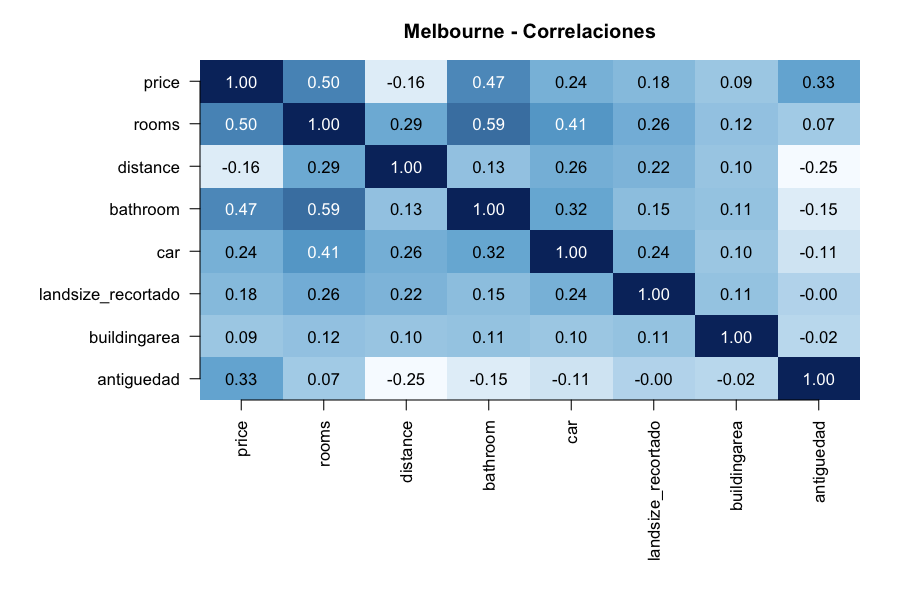

In [70]:
mapa_calor(cor_melb, "Melbourne - Correlaciones")

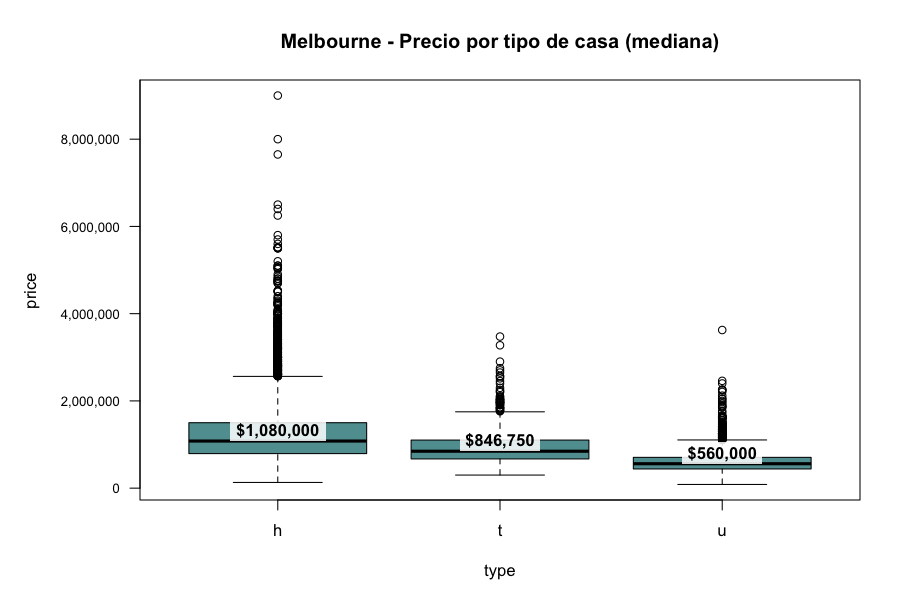

In [71]:
par(mar = c(5, 7, 4, 2))
caja <- boxplot(price ~ type, data = melb, col = "cadetblue", yaxt = "n",
                main = "Melbourne - Precio por tipo de casa (mediana)", xlab = "type", ylab = "")
eje_y_completo(melb$price)
title(ylab = "price", line = 5)

medianas <- caja$stats[3, ]
etiquetas_medianas(medianas, paste0("$", trimws(format(medianas, big.mark = ","))))

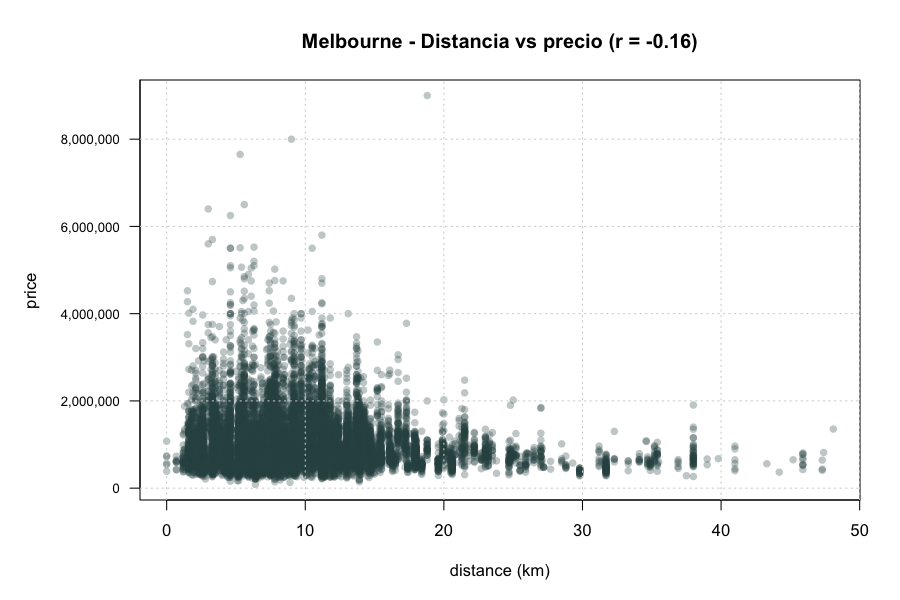

In [72]:
r <- cor(melb$distance, melb$price)

par(mar = c(5, 7, 4, 2))
plot(melb$distance, melb$price, col = adjustcolor("darkslategray", alpha.f = 0.3), pch = 16, yaxt = "n",
     main = paste0("Melbourne - Distancia vs precio (r = ", round(r, 2), ")"),
     xlab = "distance (km)", ylab = "")
eje_y_completo(melb$price)
title(ylab = "price", line = 5)
grid()

## Conclusiones

- Spotify: la popularidad de la canción se relaciona con la popularidad del artista (0.47). Los singles duran menos que las canciones de álbum. Casi el 40% de las canciones no tiene género.
- Airbnb: price y service_fee tienen correlación de 1 porque la tarifa es más o menos el 20% del precio. El precio casi no cambia entre zonas ni tipos de habitación y no se relaciona con las reseñas.
- Melbourne: el precio sube con los cuartos (0.50) y los baños (0.47) y baja un poco con la distancia (-0.16). Las casas (h) son las más caras y los departamentos (u) los más baratos. Las casas a 10 km o menos del centro tienen un precio mediano mayor ($980,000 contra $835,000).

# 6. Guardar datasets limpios

In [73]:
dir.create("datos_limpios", showWarnings = FALSE)

write.csv(spotify, "datos_limpios/spotify_limpio.csv", row.names = FALSE, fileEncoding = "UTF-8")
write.csv(airbnb, "datos_limpios/airbnb_limpio.csv", row.names = FALSE, fileEncoding = "UTF-8")
write.csv(melb, "datos_limpios/melbourne_limpio.csv", row.names = FALSE, fileEncoding = "UTF-8")

In [74]:
# Resumen antes y despues de la limpieza

resumen <- data.frame(
  Dataset = c("Spotify", "Airbnb", "Melbourne"),
  Filas_antes = c(nrow(df_spotify), nrow(df_airbnb), nrow(df_melb)),
  Filas_despues = c(nrow(spotify), nrow(airbnb), nrow(melb)),
  Columnas_antes = c(ncol(df_spotify), ncol(df_airbnb), ncol(df_melb)),
  Columnas_despues = c(ncol(spotify), ncol(airbnb), ncol(melb)),
  Duplicados_antes = c(sum(duplicated(df_spotify)), sum(duplicated(df_airbnb)), sum(duplicated(df_melb))),
  Duplicados_despues = c(sum(duplicated(spotify)), sum(duplicated(airbnb)), sum(duplicated(melb))),
  Archivo = c("spotify_limpio.csv", "airbnb_limpio.csv", "melbourne_limpio.csv")
)
resumen

    Dataset Filas_antes Filas_despues Columnas_antes Columnas_despues Duplicados_antes Duplicados_despues
1   Spotify        8582          8582             15               18                0                  0
2    Airbnb      102599        102058             26               27              541                  0
3 Melbourne       13580         13580             21               26                0                  0
               Archivo
1   spotify_limpio.csv
2    airbnb_limpio.csv
3 melbourne_limpio.csv
